### EXPERIMENT 1: IMAGE ADDITION

Objective: Understand pixel-wise image addition.

Tasks:
 1. Add a constant value to increase image brightness.
 2. Blend two images using weighted addition.

Question: How does adding a constant differ from blending two images?

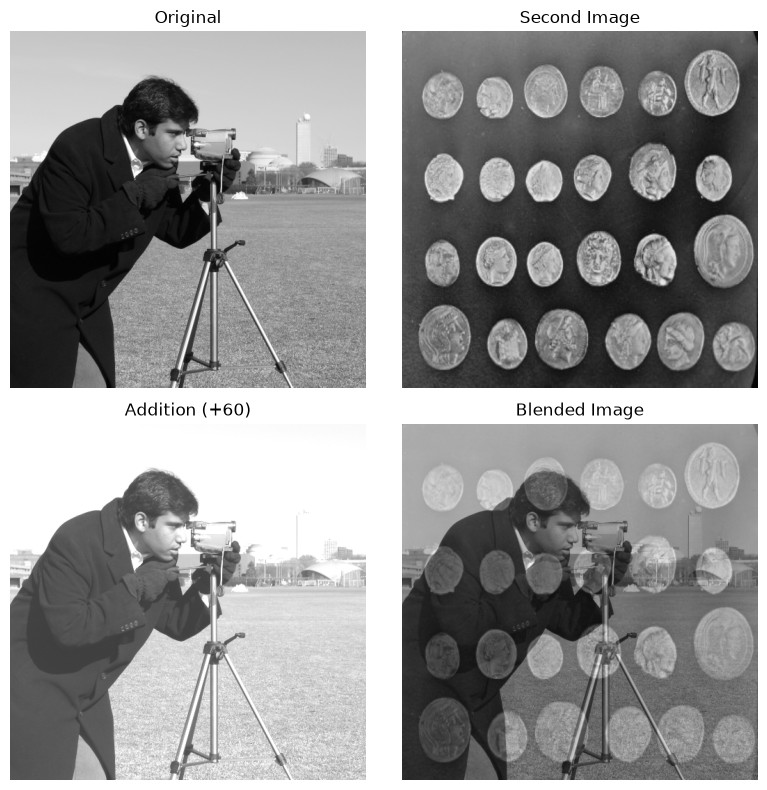

In [1]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img1 = data.camera()
img2 = data.coins()

# Resize the second image to match the first
from skimage.transform import resize
img2 = resize(img2, img1.shape, preserve_range=True).astype(np.uint8)

# Perform arithmetic in floating point to avoid overflow
bright = np.clip(img1.astype(float) + 60, 0, 255)
blended = 0.6 * img1.astype(float) + 0.4 * img2.astype(float)

images = [img1, img2, bright, blended]
titles = ["Original", "Second Image", "Addition (+60)", "Blended Image"]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, img, title in zip(axes.flat, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 2: ADDITIVE RANDOM NOISE

Objective: Investigate how random pixel-wise addition affects image quality.
Tasks:
 1. Generate Gaussian noise with different standard deviations.
 2. Add the noise to the original image.

Question: How does increasing noise variance affect image quality?

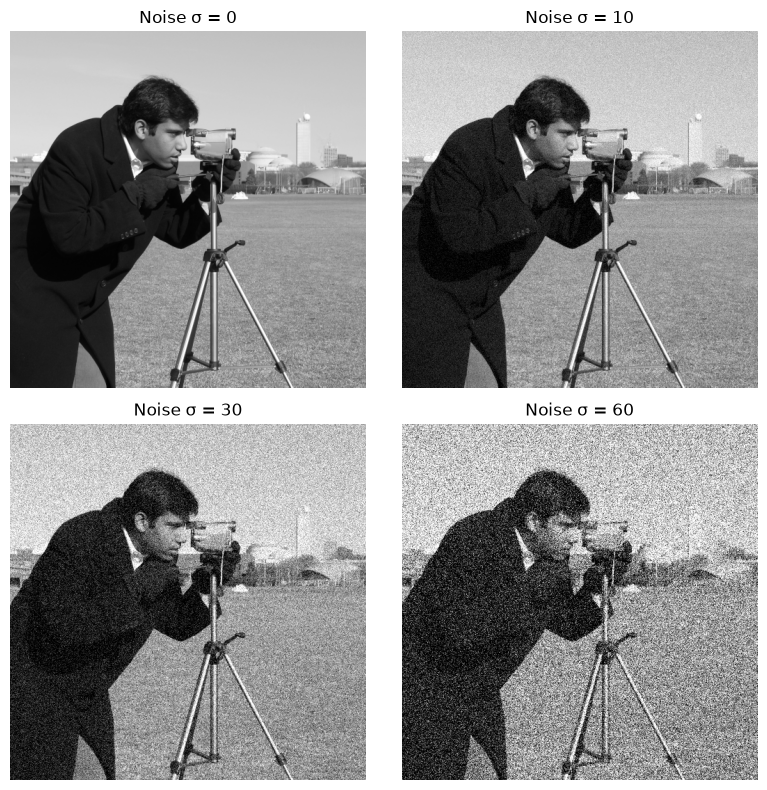

In [2]:
img = data.camera().astype(float)
rng = np.random.default_rng(42)

sigmas = [0, 10, 30, 60]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, sigma in zip(axes.flat, sigmas):
    noise = rng.normal(0, sigma, img.shape)
    noisy = np.clip(img + noise, 0, 255)

    ax.imshow(noisy, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Noise σ = {sigma}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 3: OVERFLOW AND NORMALIZATION
Objective: Understand overflow in unsigned 8-bit images.

Tasks:
 1. Observe the effect of direct uint8 addition.
 2. Compare clipping and min-max normalization.

Question: Why does uint8 arithmetic sometimes produce unexpected values?

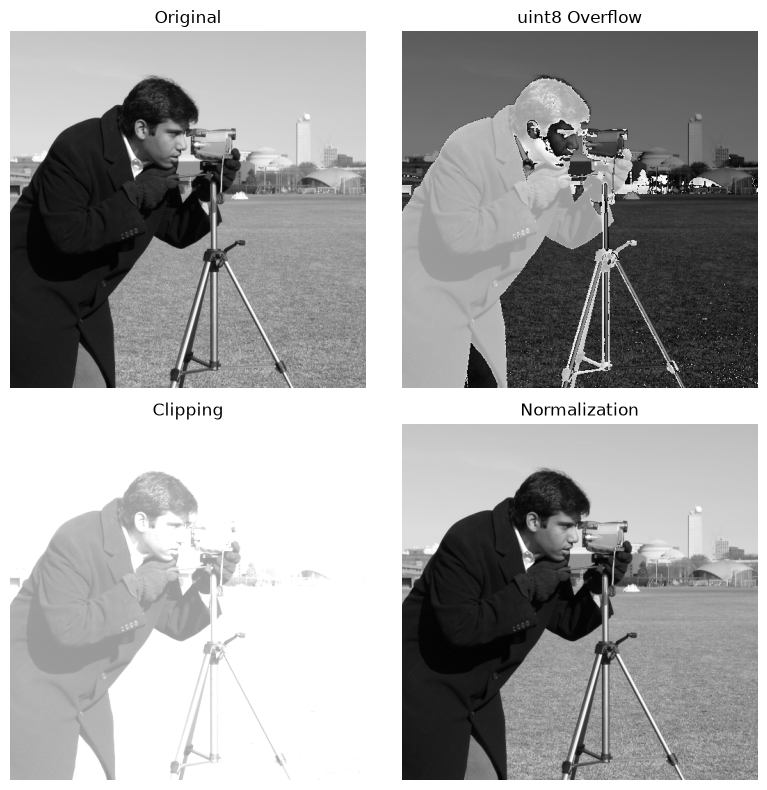

In [3]:
img = data.camera()
offset = 150

# Direct uint8 addition wraps around modulo 256
overflow = img + np.uint8(offset)

# Convert to a wider type before arithmetic
result = img.astype(np.float32) + offset

clipped = np.clip(result, 0, 255).astype(np.uint8)
normalized = (255 * (result - result.min()) /
              (result.max() - result.min())).astype(np.uint8)

images = [img, overflow, clipped, normalized]
titles = ["Original", "uint8 Overflow", "Clipping", "Normalization"]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 4: IMAGE SUBTRACTION

Objective: Investigate subtraction, underflow, and absolute differences.

Tasks:
 1. Subtract a constant from an image.
 2. Compare uint8 underflow, clipping, and absolute difference.

Question: Why must we consider data types when subtracting images?

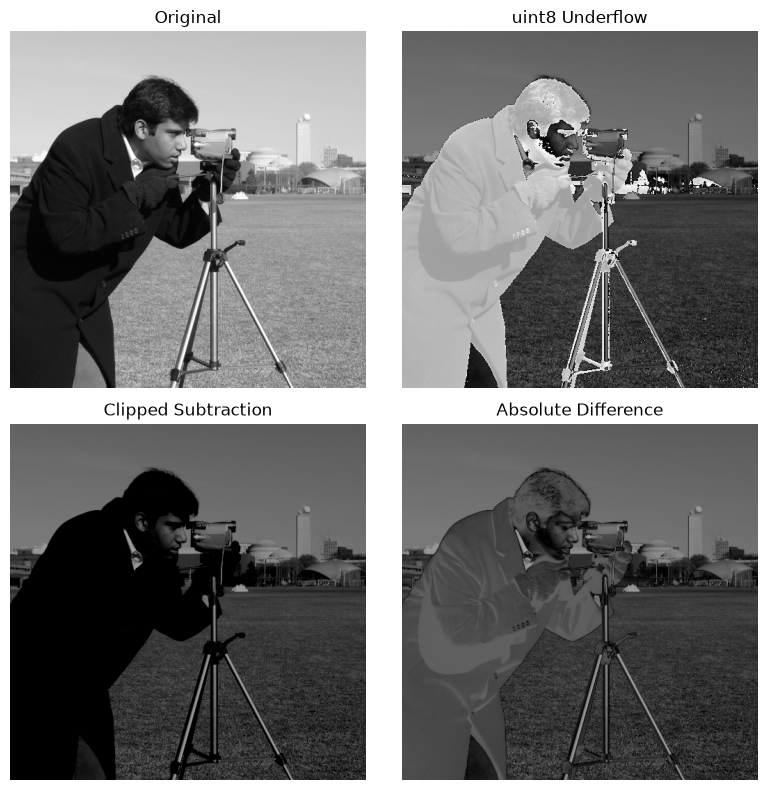

In [4]:
img = data.camera()
offset = 100

underflow = img - np.uint8(offset)

result = img.astype(np.int16) - offset
clipped = np.clip(result, 0, 255).astype(np.uint8)
absolute = np.abs(result).astype(np.uint8)

images = [img, underflow, clipped, absolute]
titles = ["Original", "uint8 Underflow", "Clipped Subtraction", "Absolute Difference"]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 5: MULTIPLICATIVE IMAGE SCALING

Objective: Investigate brightness adjustment through multiplication and division.

Tasks:
 1. Multiply image intensities by different scaling factors.
 2. Observe the effects on brightness and saturation.

Question: How does multiplicative scaling differ from additive offset?

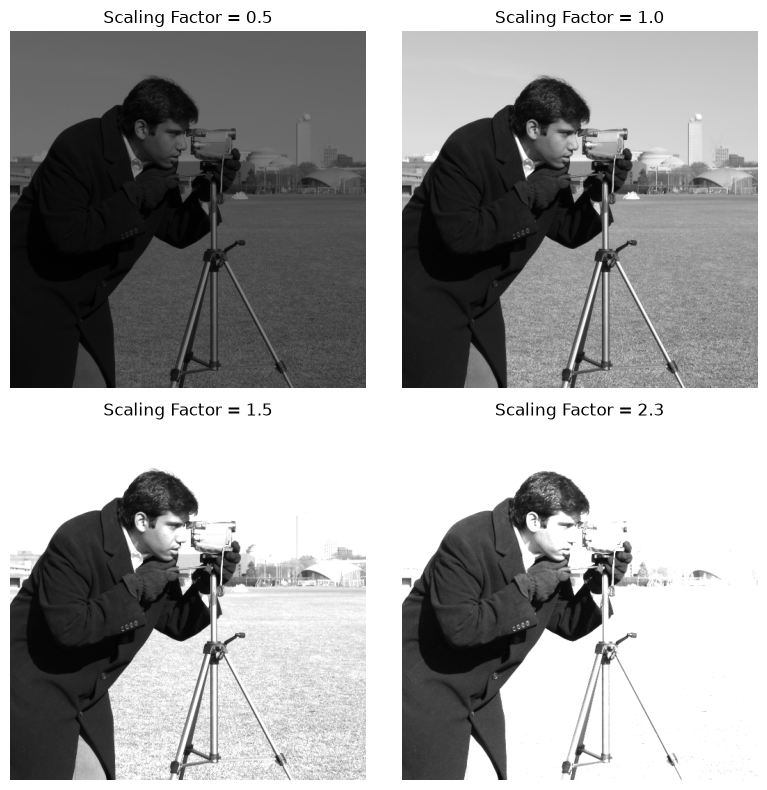

In [5]:
img = data.camera().astype(float)

factors = [0.5, 1.0, 1.5, 2.3]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, factor in zip(axes.flat, factors):
    scaled = np.clip(img * factor, 0, 255)

    ax.imshow(scaled, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Scaling Factor = {factor}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# EXPERIMENT 6: LOGICAL OPERATIONS
# Objective: Understand Boolean operations on binary images.
# Tasks:
# 1. Create two overlapping binary shapes.
# 2. Apply AND, OR, XOR, and NOT operations.
# Question: Which operation highlights regions belonging to only one shape?

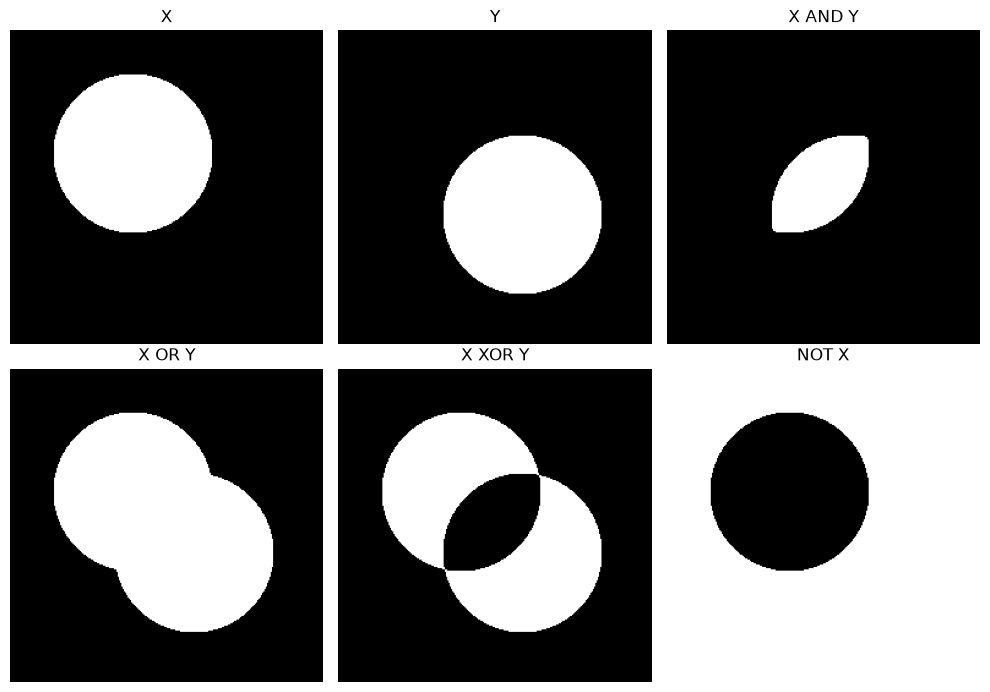

In [6]:
from skimage.draw import disk

X = np.zeros((256, 256), dtype=bool)
Y = np.zeros((256, 256), dtype=bool)

rr, cc = disk((100, 100), 65, shape=X.shape)
X[rr, cc] = True

rr, cc = disk((150, 150), 65, shape=Y.shape)
Y[rr, cc] = True

images = [
    X, Y,
    np.logical_and(X, Y),
    np.logical_or(X, Y),
    np.logical_xor(X, Y),
    np.logical_not(X)
]

titles = ["X", "Y", "X AND Y", "X OR Y", "X XOR Y", "NOT X"]

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, img, title in zip(axes.flat, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 7: IMAGE MASKING

Objective: Extract a region of interest (ROI) using a binary mask.

Tasks:
 1. Generate a circular binary mask.
 2. Apply AND and OR operations to a grayscale image.

Question: How can logical operations isolate or modify image regions?

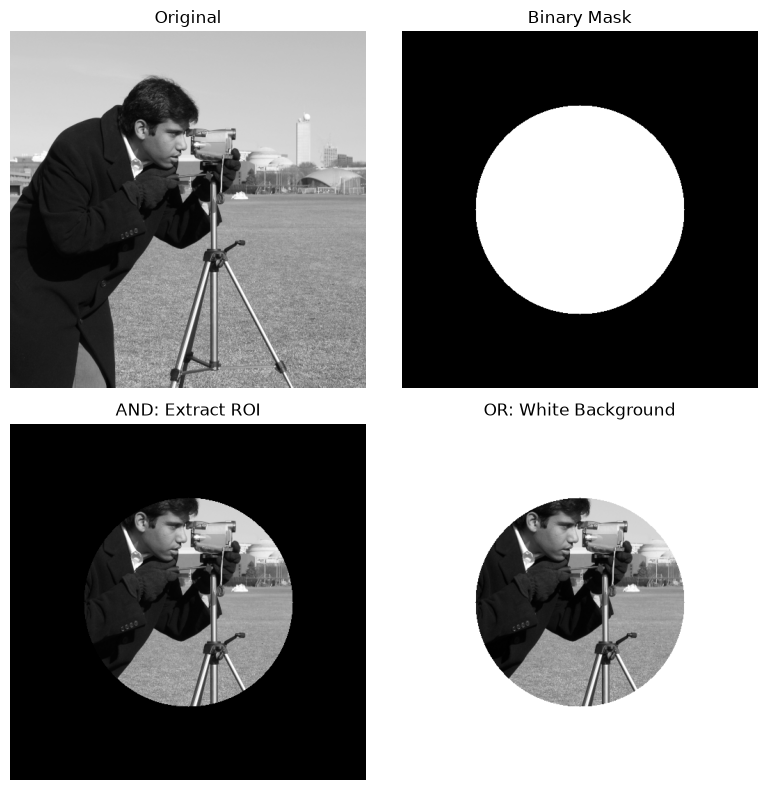

In [7]:
img = data.camera()
h, w = img.shape

Y, X = np.ogrid[:h, :w]

mask = (X - w//2)**2 + (Y - h//2)**2 <= 150**2

# Apply a binary mask using bitwise AND
masked = np.bitwise_and(img, mask.astype(np.uint8) * 255)

# Set pixels outside the ROI to white using bitwise OR
white_background = np.bitwise_or(
    img, (~mask).astype(np.uint8) * 255
)

images = [img, mask, masked, white_background]
titles = ["Original", "Binary Mask", "AND: Extract ROI", "OR: White Background"]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 8: XOR AND IMAGE DIFFERENCE

Objective: Compare logical XOR with arithmetic absolute difference.

Tasks:
 1. Generate two binary images with displaced objects.
 2. Identify changed pixels using XOR.
 3. Compare XOR and absolute difference for grayscale images.

Question: Is XOR always equivalent to absolute subtraction?

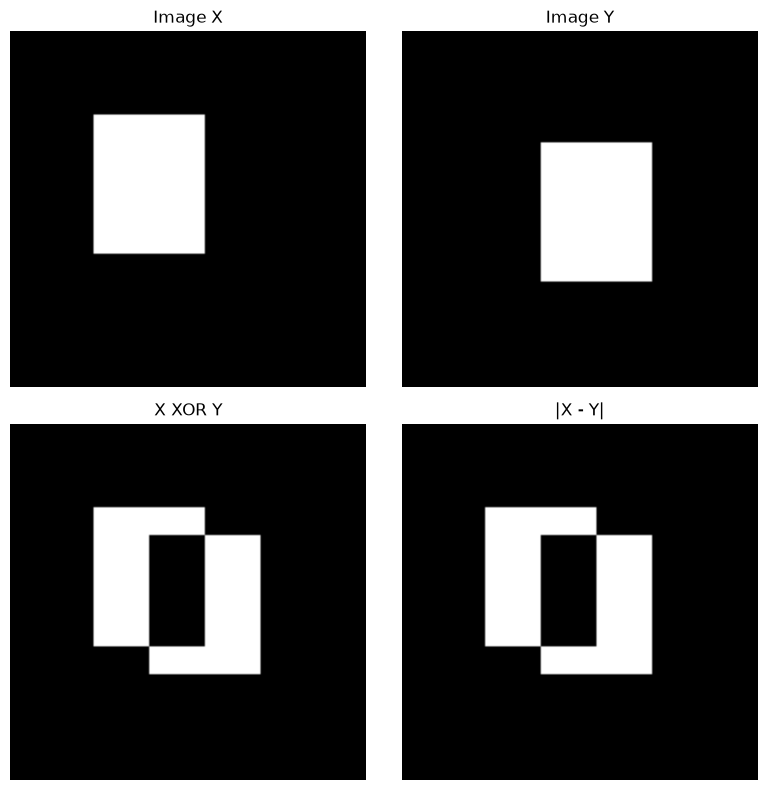

Binary results equal: True
Grayscale XOR: 172
Grayscale absolute difference: 100


In [8]:
X = np.zeros((128, 128), dtype=np.uint8)
Y = np.zeros((128, 128), dtype=np.uint8)

X[30:80, 30:70] = 1
Y[40:90, 50:90] = 1

xor_binary = np.bitwise_xor(X, Y)
diff_binary = np.abs(X.astype(int) - Y.astype(int))

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

images = [X, Y, xor_binary, diff_binary]
titles = ["Image X", "Image Y", "X XOR Y", "|X - Y|"]

for ax, img, title in zip(axes.flat, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# For binary 0/1 images, XOR equals absolute difference.
print("Binary results equal:", np.array_equal(xor_binary, diff_binary))

# For grayscale intensities, the two operations generally differ.
a, b = np.uint8(200), np.uint8(100)

print("Grayscale XOR:", np.bitwise_xor(a, b))
print("Grayscale absolute difference:", abs(int(a) - int(b)))